In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from PIL import Image
import imageio.v2 as imageio
from tqdm import tqdm

In [ ]:
VIDEO_PATH = '/home/aarushi/Detecting-Deepfakes/AI_Video_Generation_Dataset/sora/2.mp4'  
FRAME_LIMIT = None            
PATCHES_PER_FRAME = 50
FRAME_SIZE = 256               
PATCH_SIZE = 32               

#  Butterworth Filter Parameters 
cutoff = 10
fs = 100
order = 2
btype = 'low'

b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

spectra = []

#  Load video and iterate through frames 
reader = imageio.get_reader(VIDEO_PATH)
frame_count = 0

for frame in tqdm(reader, desc="Processing video frames"):
    if FRAME_LIMIT and frame_count >= FRAME_LIMIT:
        break

    try:
        #  Convert frame to grayscale with PIL 
        img = Image.fromarray(frame).convert('L')
        img = img.resize((FRAME_SIZE, FRAME_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping frame {frame_count}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, FRAME_SIZE, PATCH_SIZE):
        for x in range(0, FRAME_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_FRAME:
                break
        if len(patches) == PATCHES_PER_FRAME:
            break

    # Process each patch 
    for patch in patches:
        # Low-pass filter
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        # High-pass = original - low-pass
        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

    frame_count += 1

reader.close()

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum from Video Frames")
plt.axis('off')
plt.tight_layout()
output_path = 'output/sora-spectrum.png'  # <-- Change filename/path if needed
plt.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()


Processing video frames:   0%|          | 496/9223372036854775807 [03:38<1020902895170423:45:04,  2.51it/s]

Processing video frames:   0%|          | 560/9223372036854775807 [04:00<1098480625103388:18:08,  2.33it/s]


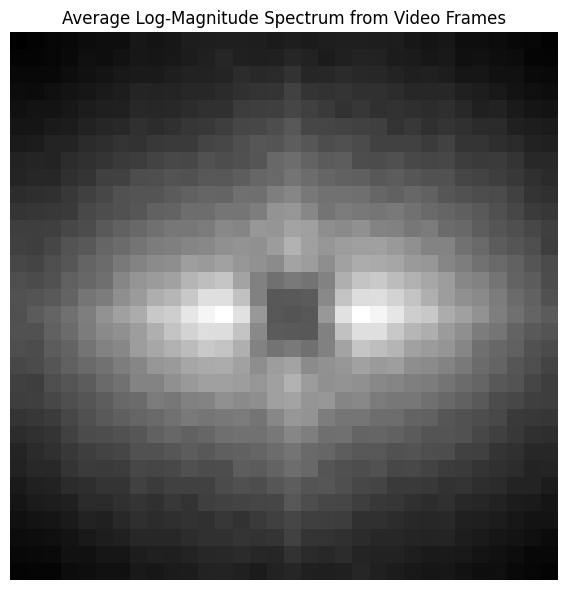

In [2]:
VIDEO_PATH = '/home/aarushi/Detecting-Deepfakes/AI_Video_Generation_Dataset/real/1.mp4'  
FRAME_LIMIT = None            
PATCHES_PER_FRAME = 50
FRAME_SIZE = 256               
PATCH_SIZE = 32               

#  Butterworth Filter Parameters 
cutoff = 10
fs = 100
order = 2
btype = 'low'

b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

spectra = []

#  Load video and iterate through frames 
reader = imageio.get_reader(VIDEO_PATH)
frame_count = 0

for frame in tqdm(reader, desc="Processing video frames"):
    if FRAME_LIMIT and frame_count >= FRAME_LIMIT:
        break

    try:
        #  Convert frame to grayscale with PIL 
        img = Image.fromarray(frame).convert('L')
        img = img.resize((FRAME_SIZE, FRAME_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping frame {frame_count}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, FRAME_SIZE, PATCH_SIZE):
        for x in range(0, FRAME_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_FRAME:
                break
        if len(patches) == PATCHES_PER_FRAME:
            break

    # Process each patch 
    for patch in patches:
        # Low-pass filter
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        # High-pass = original - low-pass
        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

    frame_count += 1

reader.close()

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum from Video Frames")
plt.axis('off')
plt.tight_layout()
output_path = 'output/real-spectrum.png'  # <-- Change filename/path if needed
plt.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()

Processing video frames:   0%|          | 560/9223372036854775807 [03:58<1090734858016178:54:56,  2.35it/s]


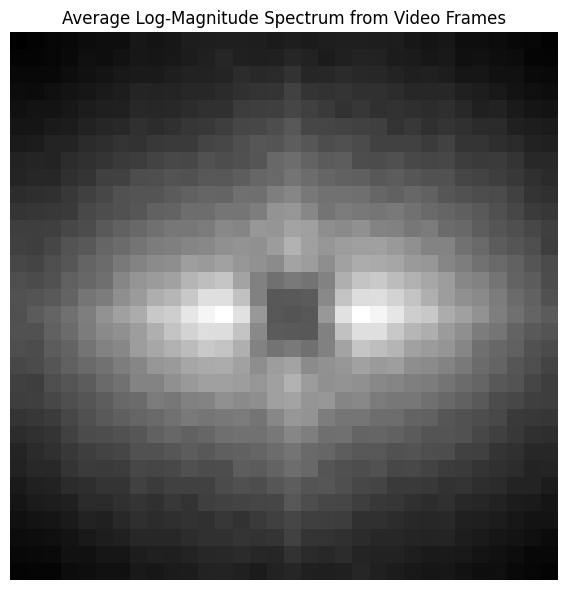

In [6]:
VIDEO_PATH = '/home/aarushi/Detecting-Deepfakes/AI_Video_Generation_Dataset/real/1.mp4'  
FRAME_LIMIT = None            
PATCHES_PER_FRAME = 50
FRAME_SIZE = 256               
PATCH_SIZE = 32               

#  Butterworth Filter Parameters 
cutoff = 10
fs = 100
order = 2
btype = 'low'

b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

spectra = []

#  Load video and iterate through frames 
reader = imageio.get_reader(VIDEO_PATH)
frame_count = 0

for frame in tqdm(reader, desc="Processing video frames"):
    if FRAME_LIMIT and frame_count >= FRAME_LIMIT:
        break

    try:
        #  Convert frame to grayscale with PIL 
        img = Image.fromarray(frame).convert('L')
        img = img.resize((FRAME_SIZE, FRAME_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping frame {frame_count}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, FRAME_SIZE, PATCH_SIZE):
        for x in range(0, FRAME_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_FRAME:
                break
        if len(patches) == PATCHES_PER_FRAME:
            break

    # Process each patch 
    for patch in patches:
        # Low-pass filter
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        # High-pass = original - low-pass
        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

    frame_count += 1

reader.close()

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum from Video Frames")
plt.axis('off')
plt.tight_layout()
output_path = 'output/real-spectrum.png'  # <-- Change filename/path if needed
plt.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()